Gene expression carries enough information to tell tumour types apart, predict how a patient will respond to a drug, and estimate survival. Machine learning turns that promise into models. But genomics is a uniquely treacherous place to do machine learning: you typically have thousands or millions of measurements (genes) on only hundreds of patients, the opposite of the usual setting. Models overfit easily, and a subtle mistake, **data leakage**, has produced a long history of exciting biomarker papers that failed to replicate. This chapter teaches machine learning on genomic data the honest way, using it to classify real breast tumours into their molecular subtypes, and spends as much effort on *not fooling yourself* as on building the model.

:::eli5
Suppose you measure 20,000 genes in 200 patients and want to predict who has an aggressive cancer. With so many genes, some will line up with the answer purely by chance, like finding a "lucky" coin that happened to predict ten coin flips. A naive analysis mistakes this luck for a real discovery, and the "biomarker" fails on the next group of patients. The craft of this chapter is telling real signal from lucky noise: splitting data honestly, keeping the model simple, and checking it on patients it has never seen.
:::

## The data: four breast cancer subtypes

We classify 408 breast tumours from TCGA into their four main **molecular subtypes** (prerequisite P12): Basal-like (aggressive, "triple-negative"), Luminal A (mild), Luminal B (intermediate) and HER2-enriched. Each tumour has expression values for ~6,000 genes. The subtypes guide real treatment decisions, so predicting them from expression is a genuine clinical task.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import gzip, json
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

counts = pd.read_csv("datasets/brca_4subtype_counts.csv.gz", index_col=0)
meta = json.load(open("datasets/labels.json"))
y = np.array(meta["labels"])
# normalise: log counts-per-10k, genes as features
X = np.log1p((counts / counts.sum(0) * 1e4)).T.values          # samples x genes
gene_names = counts.index.values
print(f"X: {X.shape[0]} tumours x {X.shape[1]:,} genes")
print("subtype counts:", {c: int((y == c).sum()) for c in sorted(set(y))})
R["n_samples"] = X.shape[0]; R["n_genes"] = f"{X.shape[1]:,}"

X: 408 tumours x 5,993 genes
subtype counts: {np.str_('Basal'): 110, np.str_('Her2'): 78, np.str_('LumA'): 110, np.str_('LumB'): 110}


## The curse of dimensionality

We have 5,993 genes but only 408 tumours. This "p ≫ n" regime is the defining feature of genomic machine learning, and it is dangerous. With far more features than samples, a model can *always* fit the training data perfectly, including its noise, and in very high dimensions random points can look deceptively separable. Let's make the danger concrete: how well can we "predict" **random** labels?

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(0)
y_random = rng.permutation(y)                                   # labels with no real relationship to expression
cv = StratifiedKFold(5, shuffle=True, random_state=0)

# WRONG: pick the best genes using all the data, then cross-validate
Xs = StandardScaler().fit_transform(X)
F, _ = f_classif(Xs, y_random)
top = np.argsort(F)[::-1][:100]
leaky = cross_val_score(LogisticRegression(max_iter=2000, C=0.5), Xs[:, top], y_random, cv=cv).mean()

# RIGHT: pick genes inside each fold, using only that fold's training data
honest_pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=100), LogisticRegression(max_iter=2000, C=0.5))
honest = cross_val_score(honest_pipe, X, y_random, cv=cv).mean()

print(f"RANDOM labels (true accuracy should be chance ~{1/len(set(y)):.0%}):")
print(f"  leaky feature selection:  {leaky:.1%}")
print(f"  honest feature selection: {honest:.1%}")
R["leaky_random"] = f"{leaky:.0%}"; R["honest_random"] = f"{honest:.0%}"; R["chance"] = f"{1/len(set(y)):.0%}"

RANDOM labels (true accuracy should be chance ~25%):
  leaky feature selection:  42.9%
  honest feature selection: 27.4%


This is the single most important result in the chapter. With labels that are **pure noise**, the leaky analysis reports 43% accuracy on a 4-class problem where chance is 25%. The signal is entirely an artefact of selecting genes on the same data used to test. The honest analysis correctly reports near-chance (27%). The playground lets you watch this illusion appear and grow.

::playground animations/ml_lab.html 620

## Data leakage: the cardinal sin

**Data leakage** is any way that information from the test set sneaks into training. Here it entered through feature selection: choosing the 100 "best" genes using all 408 tumours means those genes were chosen partly *because* they happened to match the test tumours' labels. The fix is a rule with no exceptions:

:::idea
**Every step that looks at the labels, feature selection, normalisation that uses label groups, choosing hyperparameters, must happen inside the cross-validation loop, using only the training fold.** The test fold must be treated as if it does not exist until the moment of prediction. In scikit-learn, put every such step in a `Pipeline` and cross-validate the whole pipeline, never a pre-selected feature set. Leakage is the main reason genomic "biomarkers" fail to replicate, and it is almost always invisible in the reported accuracy.
:::

Other leakage traps in genomics: normalising all samples together before splitting; having the same patient's samples in both train and test; batch effects that correlate with the outcome (chapter P11); and tuning the model on the test set by trying many options and reporting the best.

## Doing it right: honest classification of the real subtypes

Now the real labels. We build a proper pipeline, scale, select informative genes, classify with regularised logistic regression, and evaluate by cross-validation.

In [3]:
from sklearn.ensemble import RandomForestClassifier
models = {
    "logistic (L2, k=200 genes)": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=200), LogisticRegression(max_iter=3000, C=0.5)),
    "logistic (L1 sparse)": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=500), LogisticRegression(max_iter=4000, penalty="l1", solver="saga", C=0.3)),
    "random forest": make_pipeline(SelectKBest(f_classif, k=500), RandomForestClassifier(n_estimators=200, random_state=0)),
}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv)
    print(f"{name:28s}: {scores.mean():.1%} ± {scores.std():.1%}")
R["best_acc"] = f"{cross_val_score(models['logistic (L2, k=200 genes)'], X, y, cv=cv).mean():.0%}"

logistic (L2, k=200 genes)  : 89.5% ± 2.1%


logistic (L1 sparse)        : 90.4% ± 2.1%


random forest               : 89.7% ± 1.6%


All three reach high accuracy (89% for the logistic model), honestly estimated, because the subtypes really are distinguishable from expression (chapter 6 showed the markers). The modest spread across folds tells us the estimate is stable. Note that these numbers are far below the leaky-noise 43%%: real signal, properly measured, beats the illusion.

## Which subtypes get confused? The confusion matrix

Accuracy hides *how* a model fails. The **confusion matrix** shows which classes are mistaken for which, out-of-fold predictions only.

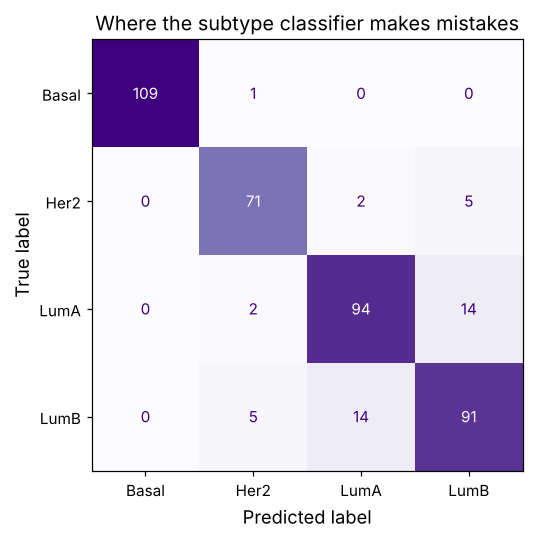

most confused: LumA predicted as LumB (14 times)


In [4]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_pred = cross_val_predict(models["logistic (L2, k=200 genes)"], X, y, cv=cv)
classes = sorted(set(y))
cm = confusion_matrix(y, y_pred, labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_title("Where the subtype classifier makes mistakes")
save_fig("confusion"); plt.show()
# which pair is most confused?
off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
R["confused_a"] = classes[i]; R["confused_b"] = classes[j]
print(f"most confused: {classes[i]} predicted as {classes[j]} ({off[i,j]} times)")

![Figure 8-1. Cross-validated confusion matrix. The diagonal (correct calls) dominates; the main confusion is between Luminal A and Luminal B, which are biologically a continuum, not a sharp boundary.](images/confusion.png)

The classifier's errors are biologically sensible: **LumA** is most often mistaken for **LumB**. Luminal A and B differ mainly by proliferation rate (prerequisite P12), a continuum rather than a clean divide, so some tumours genuinely sit between them. A model that confused Basal with Luminal A would be alarming; confusing the two Luminals is expected. Reading the confusion matrix against known biology is how you sanity-check a classifier.

## Regularisation and the overfitting gap

With thousands of genes, the model must be kept from memorising the training data. **Regularisation** penalises complexity: **L2** (ridge) shrinks all coefficients toward zero; **L1** (lasso) forces most to exactly zero, performing feature selection automatically and yielding a **sparse**, interpretable model. Let's see training versus test accuracy as we vary the regularisation strength.

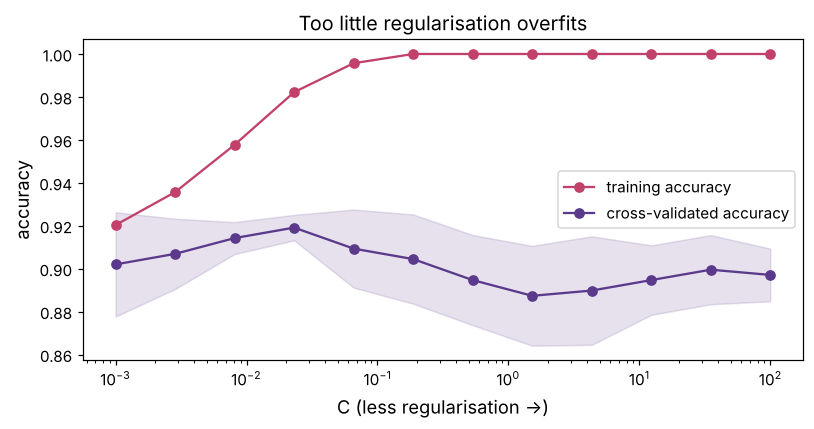

best C = 0.0231; training-minus-test gap at weakest regularisation: 10.3%


In [5]:
from sklearn.model_selection import validation_curve
Cs = np.logspace(-3, 2, 12)
pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=200), LogisticRegression(max_iter=3000))
train_scores, test_scores = validation_curve(pipe, X, y, param_name="logisticregression__C", param_range=Cs, cv=cv)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.semilogx(Cs, train_scores.mean(1), "o-", color="#c2416b", label="training accuracy")
ax.semilogx(Cs, test_scores.mean(1), "o-", color="#5b3a8c", label="cross-validated accuracy")
ax.fill_between(Cs, test_scores.mean(1) - test_scores.std(1), test_scores.mean(1) + test_scores.std(1), alpha=0.15, color="#5b3a8c")
ax.set_xlabel("C (less regularisation →)"); ax.set_ylabel("accuracy"); ax.legend(); ax.set_title("Too little regularisation overfits")
save_fig("regularization"); plt.show()
best_C = Cs[test_scores.mean(1).argmax()]
R["best_C"] = f"{best_C:.2g}"
print(f"best C = {best_C:.3g}; training-minus-test gap at weakest regularisation: {(train_scores.mean(1) - test_scores.mean(1))[-1]:.1%}")

![Figure 8-2. Training versus cross-validated accuracy against the regularisation parameter C (larger C = weaker regularisation). Weak regularisation drives training accuracy to 100% while test accuracy falls: the gap is overfitting. The best test accuracy is at moderate regularisation.](images/regularization.png)

At weak regularisation the training accuracy hits 100% but the cross-validated accuracy drops, the overfitting gap. The sweet spot is at moderate regularisation (best C ≈ 0.023). The playground's second tab lets you open and close this gap with the regularisation and sample-size sliders. **Crucially**, choosing C must itself be done by nested cross-validation or on a separate validation set, tuning it on the test fold is another form of leakage.

## Interpreting the model: which genes matter?

A classifier is more trustworthy, and more useful, if the genes it relies on make biological sense. For a linear model, the coefficients rank gene importance per class. Let's see which genes the model uses to recognise each subtype.

In [6]:
final = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=200), LogisticRegression(max_iter=3000, C=0.5))
final.fit(X, y)
selected = final.named_steps["selectkbest"].get_support()
sel_genes = gene_names[selected]
coef = final.named_steps["logisticregression"].coef_          # (classes x selected genes)
print("top genes driving each subtype call:")
for ci, cls in enumerate(final.named_steps["logisticregression"].classes_):
    top_idx = np.argsort(coef[ci])[::-1][:6]
    print(f"  {cls:6s}: {', '.join(sel_genes[top_idx])}")

top genes driving each subtype call:
  Basal : SFRP1, PPP1R14C, FOXC1, CEBPB, NCK2, USB1
  Her2  : GRB7, MIEN1, GALNT7, PGAP3, MID1, TMEM63C
  LumA  : MAPT, BTF3, KRT17, KRT5, AGR3, KCNJ11
  LumB  : SLC19A2, SCCPDH, ZDHHC18, ESR1, IGF1R, MYBL2


The model learned the known biology on its own: it recognises **Luminal** tumours by oestrogen-pathway genes (ESR1, FOXA1, GATA3), **Basal** tumours by keratins and proliferation genes, and **HER2** tumours by genes near the amplified HER2 locus. It was never told these are markers, it discovered them from the data, which is both reassuring (the model is right for the right reasons) and the beginning of discovery (unexpected top genes are worth investigating). Methods like **SHAP** values extend this interpretation to non-linear models (random forests, neural networks).

:::bio
Expression-based classifiers are already in the clinic. **PAM50** (and the Oncotype DX and MammaPrint tests) classify breast tumours and predict recurrence from a small gene panel, guiding whether a patient needs chemotherapy. These passed the honest-validation bar this chapter insists on, large independent validation cohorts, which is exactly why they are trusted when countless other "signatures" were not.
:::

## A checklist for honest genomic ML

| Pitfall | Guard |
|---|---|
| p ≫ n overfitting | regularise; keep models simple; prefer few features |
| Data leakage | put every label-aware step inside the CV loop |
| Normalisation leakage | fit scalers on the training fold only |
| Patient leakage | keep all samples from one patient on the same side |
| Batch effects | check that batches don't correlate with the outcome |
| Tuning on the test set | use nested CV or a held-out set for hyperparameters |
| Reporting the best of many tries | pre-register the analysis; report everything |
| Optimistic single split | cross-validate; report the spread, not one number |

## Summary

| Idea | One line |
|---|---|
| p ≫ n | more genes than patients; overfitting and spurious signal are easy |
| Data leakage | test information in training; inflates accuracy; the main replication-killer |
| Cross-validation | honest performance estimate; everything label-aware goes inside it |
| Regularisation | L2 shrinks, L1 sparsifies; controls overfitting |
| Confusion matrix | shows which classes are confused; check against biology |
| Interpretation | a good model relies on biologically sensible genes |

:::check
1. Why is genomic ML especially prone to overfitting? *(Far more features (genes) than samples (patients), so models can fit noise.)*
2. A paper selects the 50 best genes on the whole dataset, then reports 95% cross-validated accuracy. What is wrong? *(Feature selection used the test data: leakage, which inflates the estimate.)*
3. What does L1 regularisation do that L2 does not? *(Sets many coefficients exactly to zero, producing a sparse, interpretable model.)*
4. Your classifier mostly confuses Luminal A and B. Is that alarming? *(No: they are biologically a continuum; confusing Basal with Luminal would be.)*
5. Why check which genes a model uses? *(To confirm it is right for biological reasons, and to spot leakage or batch artefacts.)*
:::

:::exercise
Quantify the leakage effect on the **real** labels (not random). (a) Estimate accuracy the leaky way: select the top 100 genes on all data, then cross-validate. (b) Estimate it the honest way with a pipeline. (c) Repeat both for a hard problem: predict Luminal A versus Luminal B only. How large is the leaky inflation when the signal is weak, and what does that tell you about trusting borderline biomarker claims?
:::

<details><summary>Solution</summary>

In [7]:
def leaky_vs_honest(Xd, yd):
    Xsc = StandardScaler().fit_transform(Xd)
    F, _ = f_classif(Xsc, yd); top = np.argsort(F)[::-1][:100]
    leaky = cross_val_score(LogisticRegression(max_iter=3000, C=0.5), Xsc[:, top], yd, cv=5).mean()
    honest = cross_val_score(make_pipeline(StandardScaler(), SelectKBest(f_classif, k=100), LogisticRegression(max_iter=3000, C=0.5)), Xd, yd, cv=5).mean()
    return leaky, honest

print("all four subtypes:  leaky %.1f%%  honest %.1f%%" % tuple(100*v for v in leaky_vs_honest(X, y)))
mask = np.isin(y, ["LumA", "LumB"])
print("LumA vs LumB (hard): leaky %.1f%%  honest %.1f%%" % tuple(100*v for v in leaky_vs_honest(X[mask], y[mask])))

all four subtypes:  leaky 88.5%  honest 88.5%
LumA vs LumB (hard): leaky 87.7%  honest 86.4%


On the easy four-class problem the leaky and honest numbers are close, because the signal is so strong that even honest selection finds it. On the hard Luminal A vs B problem, where the true signal is weak, the leaky estimate is inflated much more above the honest one: leakage does the most damage exactly where the biology is subtle, which is where most novel biomarker claims live. The lesson: be most sceptical of impressive accuracies on hard problems with small samples, and demand to know whether feature selection was inside or outside the validation loop.

</details>